## Imports and functions

### Import

In [212]:
import os
import json
import matplotlib.pyplot as plt
import numpy as np
from collections import defaultdict
from scipy.stats import sem, t, norm
import random
from matplotlib.patches import Rectangle


### Constants

In [213]:

dir_path = 'jsonFiles/'

GENERAL = "General"
MONOTONICITY_TEST = "TEST_monotonicity"
CONTINUITY_TEST = "TEST_continuity"
CONSISTENCY_TEST_DOUBLE_RATES = "TEST_consistency_doubleRates"
CONSISTENCY_TEST_onlyCars = "TEST_consistency_onlyCars"
CONSISTENCY_TEST_onlyTrucks = "TEST_consistency_onlyTrucks"
CALIBRATION_SERVICE_TIME = "CALIB_ServiceTime"

STD_LANE_0 = "HighwayBarrier.barrier.stdLane[0]"
ETC_LANE_0 = "HighwayBarrier.barrier.etcLane[0]"

# Statistic names
WAITING_TIME_STAT = 'WaitingTime'
RESPONSE_TIME_STAT = 'ResponseTime'
CARS_IN_QUEUE_STAT = 'CarsInQueue'
TOTAL_CARS_STAT = 'TotalCars'

# Parameter names in 'config'
CONFIG_PARAM_N = "**.barrier.N"
CONFIG_PARAM_std_lane_mean = "**.barrier.stdLane[*].mean"
CONFIG_PARAM_cars_arrival_rate = "**.highway.Tc"


SHOW_GRAPHS = True
SAVE_GRAPH_FILES = True



### Functions

#### deleteUnitOfMeasurement

In [214]:
def deleteUnitOfMeasurement(group_by_config, param_value):
      if    group_by_config == CONFIG_PARAM_std_lane_mean or \
            group_by_config == CONFIG_PARAM_cars_arrival_rate:
            # Remove the trailing character
            return param_value[:-1]
      elif group_by_config == CONFIG_PARAM_N:
            return param_value
      else:
            return param_value

#### GroupScalarsByConfigurationParameter

In [215]:
def GroupScalarsByConfigurationParameter(file_name, module_name, stat_source, group_by_config):
      """
            Extracts data filtered by module and statistic, and returns it grouped by the field specified in group_by.

            Args:
                  file_name   (str): The file name.
                  module_name (str): The module name.
                  stat_source (str): The value of attributes->source.
                  group_by_config:   The configuration field used to group the values

            Returns:
            dict: A map from {group_by_config} (distinct value) to arrays of values of the statistic.
      """

      # Create file path
      file_path = os.path.join(dir_path, f"{file_name}.json")

      # Open json file
      with open(file_path, 'r') as file:
            data = json.load(file)

      # Dictionary
      data_dict = defaultdict(list)

      for key, content in data.items():

            # Look up the value directly in the list of configuration parameters
            group_param = None
            for param in content.get("config", []):
                  if group_by_config in param:
                        group_param = param[group_by_config]
                        break

            group_param = deleteUnitOfMeasurement(group_by_config, group_param)

            # Check whether scalars exist and filter by module and source
            for scalar in content.get("scalars", []):
                  if scalar["module"] == module_name and scalar["attributes"].get("source") == stat_source:
                        data_dict[group_param].append(scalar["value"])

      return data_dict

#### ConstructBarChart

In [216]:

def ConstructBarChart(data_dict, confidence_level, colors, hatches=None, width=10, height=6):
      """
      Generates a bar chart with error bars representing the confidence interval, and optional hatches.

      Args:
            data_dict (dict): Dictionary with values of N as keys and arrays of values.
            confidence_level (float): The confidence level (e.g. 0.95 for 95%).
            colors (list): List of colors for the bars.
            hatches (list): List of patterns (e.g. ['/', 'x', 'o']).
            width (float): Width of the chart.
            height (float): Height of the chart.

      Returns:
            plt: The plot with the bar chart and empty titles to be filled in.
      """
      means = []
      conf_intervals = []
      GroupParamValues = []

      for groupParam, values in data_dict.items():
            # Compute the mean of the values for a given groupParam
            mean = np.mean(values)

            # Compute its confidence interval
            ci_interval = ConfidenceInterval(values, confidence_level)

            # Append to the final arrays to plot
            means.append(mean)
            conf_intervals.append(ci_interval)
            GroupParamValues.append(groupParam)

      # Sort the three arrays by groupParam value
      sorted_items = sorted(zip(GroupParamValues, means, conf_intervals), key=lambda x: float(x[0]))
      GroupParamValues, means, conf_intervals = zip(*sorted_items)

      fig, ax = plt.subplots(figsize=(width, height))
      
      # Add the bars with hatches and zorder for correct overlap
      if hatches is None:
            hatches = [None] * len(GroupParamValues)

      bars = []
      for i, (groupParam, mean, color, hatch) in enumerate(zip(GroupParamValues, means, colors[:len(GroupParamValues)], hatches)):
            bar = ax.bar(
                  groupParam, mean, color=color, hatch=hatch, width=0.5, label=f"{groupParam}", zorder=2
            )
            bars.append(bar)

      ax.errorbar(GroupParamValues, means, yerr=conf_intervals, fmt='none', color='black', capsize=5, zorder=3)

      # Add the grid below the bars
      ax.grid(True, color='#a0a0a0', linestyle='--', linewidth=0.5, axis='y', zorder=1)

      ax.set_xlabel("--- x-axis label --- (unit)")
      ax.set_ylabel("--- y-axis label --- (unit)")
      ax.set_title("--- metti un titolo ---")

      return plt

#### ConfidenceInterval

In [217]:
def ConfidenceInterval(data, level):
      '''
            data:       array di campioni
            level:      confidence interval level (es: 95% -> 0.95)
      '''
      mean = np.mean(data)
      std_dev = np.std(data, ddof=1)
      n = len(data)
      z = norm.ppf(1 - (1 - level) / 2)

      interval = z * (std_dev / np.sqrt(n))

      return interval

#### CollectScalars

In [218]:
def CollectScalars(file_name, module_name, stat_name):
      '''
            dist_type:  distribution type (use preset)
            workload:   workload type (use preset)
            module_name:      module name, es: HighwayBarrier.barrier.stdLane[0]
            stat_name:  statistic name
      '''

      # Dictionary
      data_dict = defaultdict(lambda: defaultdict(list))

      # Create file path
      file_path = os.path.join(dir_path, f"{file_name}.json")

      # Open json file
      with open(file_path, 'r') as file:
            data = json.load(file)

      # Loop over all entries
      for config_name, entry in data.items():

            # Extract the values of p and K
            itervars = entry.get("itervars", {})
            p = float(itervars.get("p", 0))
            K = int(itervars.get("K", 0))

            scalars = entry.get("scalars", [])
            # Iterate over the scalars
            for scalar in scalars:

                  # Check that this is the requested module and statistic
                  if    scalar.get("module") == module_name and \
                        scalar.get("attributes", {}).get("source") == stat_name:

                        # Get the value
                        scalar_value = scalar.get("value")

                        # TODO
                        # Skip if out of bound

                        # Group by (K, p)
                        data_dict[K][p].append(scalar_value)

      return data_dict


#### PlotData

In [219]:
def PlotData(plot_ref, data_dict, color_maps, line_style='solid', marker_type='o', exclusions=None):
      '''
            plot_ref:   plot reference
            data_dict:  data dictionary
            color_maps: color mapping for each K value
            line_style:
                  'solid'     linea continua
                  'dashed'    linea tratteggiata
                  'dashdot'   tratto-punto
                  'dotted'    linea puntinata
            exclusions: set of (K, p) tuples to exclude from the analysis
      '''
      ci_lines_threshold = 1.75

      if exclusions is None:
            exclusions = set()
      
      for K in sorted(data_dict.keys()):  # For each K, in order
            p_values = sorted(data_dict[K].keys())  # Sort the values of p
            mean_values = []

            for p in p_values:
                  
                  # Skip the (K, p) pair if it is listed in exclusions
                  if (K, p) in exclusions:
                        continue

                  values = data_dict[K][p]
                  if values:
                        # Compute the mean of the values
                        mean_value = np.mean(values)

                        # Compute the confidence interval of the values
                        ci = ConfidenceInterval(values, 0.95)

                        # Check whether the CI is above the threshold
                        if ci > ci_lines_threshold:
                              # Draw error bars only if the CI is significant
                              plot_ref.errorbar(
                                    p,  # X value
                                    mean_value,  # Y value
                                    yerr=ci,
                                    fmt='',  # Marker type ('o' = circle)
                                    color=color_maps[K],
                                    ecolor=color_maps[K],
                                    capsize=5
                              )
                        
                        # Store the mean points for the interpolation
                        mean_values.append(mean_value)

            # Add the linear interpolation
            if p_values:
                  # Filter p_values to drop the excluded pairs
                  filtered_p_values = [p for p in p_values if (K, p) not in exclusions]
                  plot_ref.plot(
                        filtered_p_values, 
                        mean_values, 
                        color=color_maps[K], 
                        linestyle=line_style, 
                        linewidth=0.75,
                        marker=marker_type,
                        label=f'K={K}'
                  )




## Warm-up time estimation

**Notes on the file to export:**
- The code only reads the first exported statistic (`vectors[0]`), so export just one relevant statistic (e.g. waiting time) of a single module

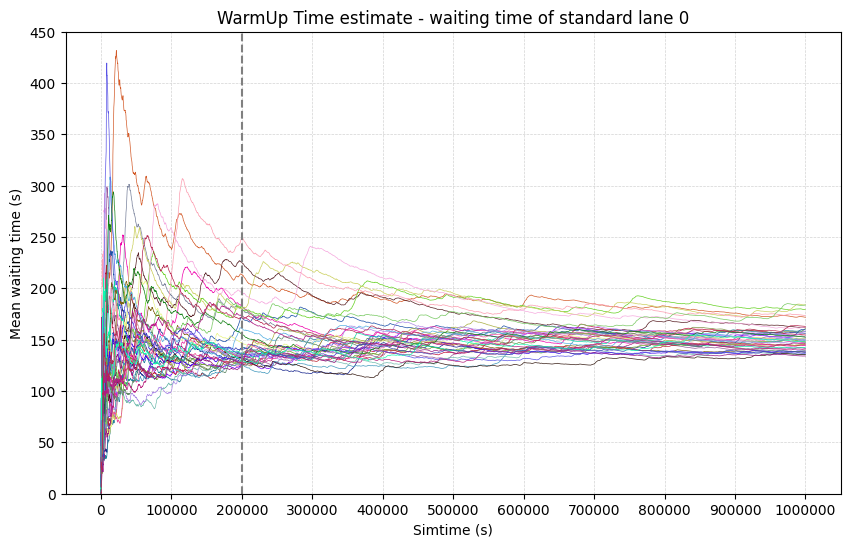

In [220]:

file_path = os.path.join("jsonFiles", f"warmuptime_estimate.json")

with open(file_path, 'r') as file:
    data = json.load(file)

plt.figure(figsize=(10, 6))

for key, entry in data.items():
      vectors = entry.get("vectors", [])

      for vector_data in vectors:
            if    vector_data.get("module") == STD_LANE_0 and \
                  vector_data.get("attributes", {}).get("source") == WAITING_TIME_STAT:

                  time = vector_data.get("time", [])
                  value = vector_data.get("value", [])

                  cumulative_avg = []  # List to store the cumulative averages
                  cumulative_sum = 0  # To store the sum of response times up to each time point

                  # Loop through the time and value arrays to calculate the cumulative average
                  for i, (t, v) in enumerate(zip(time, value)):
                        cumulative_sum += v  # Add the current response time to the sum
                        cumulative_avg.append(cumulative_sum / (i + 1))  # Compute the cumulative average
                  
                  # Plot the cumulative average response time for this workload
                  color = [random.random(), random.random(), random.random()]  # Random color for each plot
                  plt.plot(time, cumulative_avg, linewidth=0.5, color=color)

                  break


# X-axis ticks every 10^5
plt.xticks(range(0, int(1e6+1e5), int(1e5)))
plt.ticklabel_format(axis='x', style='plain')
plt.ylim(0, 450)
plt.grid(True, color='lightgray', linestyle='--', linewidth=0.5)

# Add a vertical line at x = 0.8e6
plt.axvline(x=0.2e6, color='grey', linestyle='--', label='x = 0.8e6')

plt.xlabel("Simtime (s)")
plt.ylabel("Mean waiting time (s)")
plt.title("WarmUp Time estimate - waiting time of standard lane 0")

if SAVE_GRAPH_FILES:
      fileName = 'warmup_time'
      plt.savefig(f'graphs/png/{fileName}.png', bbox_inches='tight')
      plt.savefig(f'graphs/jpg/{fileName}.jpg', bbox_inches='tight')
if SHOW_GRAPHS:
      plt.show()



# Factor Calibration

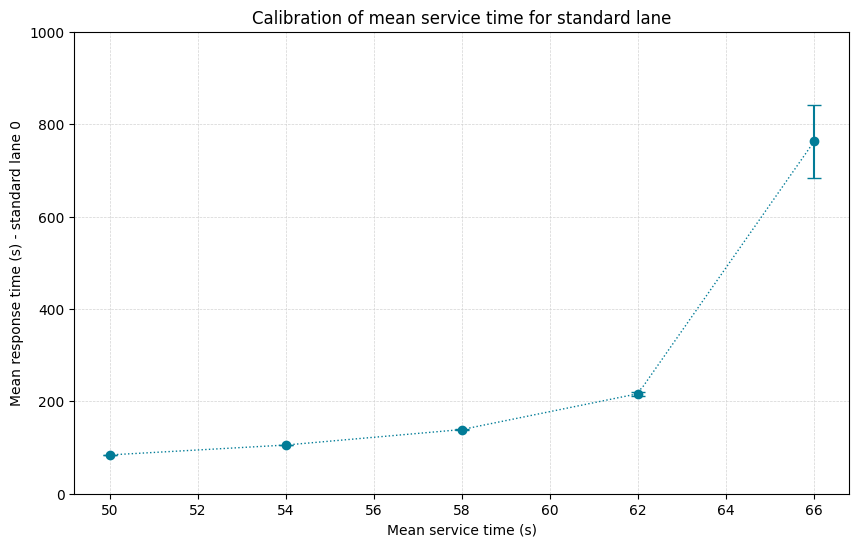

In [221]:
import matplotlib.pyplot as plt
import numpy as np
from scipy import interpolate

def PlotDataFromGroupedData(data_dict, color, line_style='solid', marker_type='o'):
      """
      Generates a chart with the points (mean values) and their linear interpolation, and adds error bars.
      
      Args:
            data_dict (dict): Dictionary with configuration values (group_by_config) as keys and arrays of values.
            color_map (dict): Dictionary mapping each value of K to a color.
            line_style (str): Line style for the interpolation (e.g. 'solid', 'dashed').
            marker_type (str): Marker type for the points (e.g. 'o', 'x').
      
      Returns:
            None
      """
      plt.figure(figsize=(10, 6))

      x_values = []
      y_values = []
      errors = []
      
      # For each configuration, compute the mean and draw the chart
      for group_param, values in data_dict.items():
            # Compute the mean of the values
            mean_value = np.mean(values)
            
            # Compute the confidence interval (CI)
            ci = ConfidenceInterval(values, 0.95)

            # Make sure group_param is numeric for the interpolation
            group_param = float(group_param)

            x_values.append(group_param)
            y_values.append(mean_value)
            errors.append(ci)

            # Plot the mean point and add the error bar
            plt.errorbar(
                  group_param,  # X value
                  mean_value,  # Y value (mean)
                  yerr=ci,  # Error bars (CI)
                  fmt=marker_type,  # Marker type ('o', 'x', etc.)
                  color=color,  # Color
                  capsize=5,  # Error bar cap width
                  label=f'{group_param} - Mean={mean_value:.2f}'  # Legend label
            )
      
      # Sort the values for the chart
      x_values = np.array(x_values)
      y_values = np.array(y_values)
      errors = np.array(errors)

      # Linear interpolation
      interpolation_function = interpolate.interp1d(x_values, y_values, kind='linear', fill_value="extrapolate")
      
      # Create new points for the interpolation
      x_new = np.linspace(min(x_values), max(x_values), 100)
      y_new = interpolation_function(x_new)
      
      # Draw the interpolation line
      plt.plot(x_new, y_new, color=color, linestyle='dotted', linewidth=1, label='Interpolazione')


      return plt

# Run the code to get the data from the file
data_dict = GroupScalarsByConfigurationParameter(
    CALIBRATION_SERVICE_TIME, 
    STD_LANE_0, 
    RESPONSE_TIME_STAT, 
    CONFIG_PARAM_std_lane_mean
)

# Define the color mapping
color = '#027c97'

# Call the function to draw the chart
PlotDataFromGroupedData(data_dict, color)

plt.ylim(0, 1000)  # Y axis starts at 0
plt.grid(True, color='lightgray', linestyle='--', linewidth=0.5)

plt.title("Calibration of mean service time for standard lane")
plt.xlabel("Mean service time (s)")
plt.ylabel("Mean response time (s) - standard lane 0")

if SAVE_GRAPH_FILES:
      fileName = 'calibration_meanServiceTime'
      plt.savefig(f'graphs/png/{fileName}.png', bbox_inches='tight')
      plt.savefig(f'graphs/jpg/{fileName}.jpg', bbox_inches='tight')
if SHOW_GRAPHS:
      plt.show()



# Test

## Continuity

The JSON file is currently exported with:
 - No vectors, scalars only
 - All scalars (waiting time, response time, cars in queue and cars total)
 - Of all modules (2 ETC lanes, 6 std lanes)

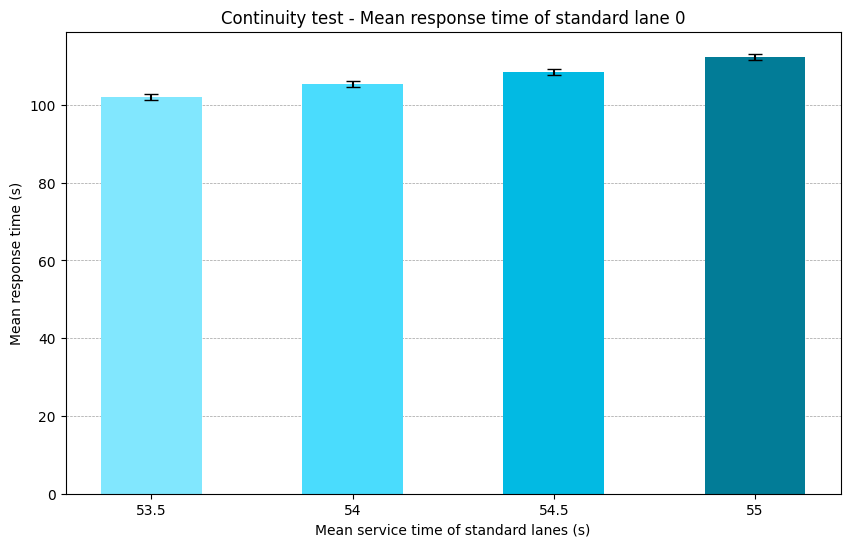

In [222]:
dictionary = GroupScalarsByConfigurationParameter(
      CONTINUITY_TEST,
      STD_LANE_0,
      RESPONSE_TIME_STAT,
      CONFIG_PARAM_std_lane_mean)

colors = ['#81e7fe', '#4adcfd', '#02bae3', '#027c97']

plt = ConstructBarChart(
      dictionary, 
      0.95, 
      colors)

plt.title("Continuity test - Mean response time of standard lane 0")
plt.xlabel("Mean service time of standard lanes (s)")
plt.ylabel("Mean response time (s)")

if SAVE_GRAPH_FILES:
      fileName = 'test_continuity'
      plt.savefig(f'graphs/png/{fileName}.png', bbox_inches='tight')
      plt.savefig(f'graphs/jpg/{fileName}.jpg', bbox_inches='tight')
if SHOW_GRAPHS:
      plt.show()


## Monotonicity

Vary the total number of lanes N in 8, 9, 10, keeping all other parameters fixed

Currently works with a file where **all** scalars of **all** modules are exported

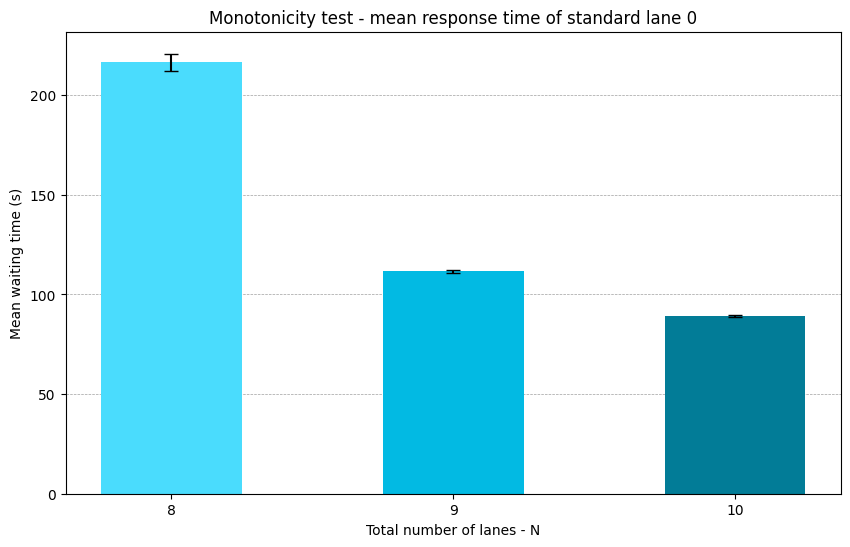

In [223]:
dictionary = GroupScalarsByConfigurationParameter(
      MONOTONICITY_TEST,
      STD_LANE_0,
      RESPONSE_TIME_STAT,
      CONFIG_PARAM_N)

colors = ['#4adcfd', '#02bae3', '#027c97']
plt = ConstructBarChart(
      dictionary, 
      0.95, 
      colors)

plt.title("Monotonicity test - mean response time of standard lane 0")
plt.xlabel("Total number of lanes - N")
plt.ylabel("Mean waiting time (s)")

if SAVE_GRAPH_FILES:
      fileName = 'test_monotonicity'
      plt.savefig(f'graphs/png/{fileName}.png', bbox_inches='tight')
      plt.savefig(f'graphs/jpg/{fileName}.jpg', bbox_inches='tight')
if SHOW_GRAPHS:
      plt.show()



## Consistency

Comparison between cars only and trucks only. No ETC-equipped vehicles, no queueing (thanks to 20 lanes and slow enough arrival rates)

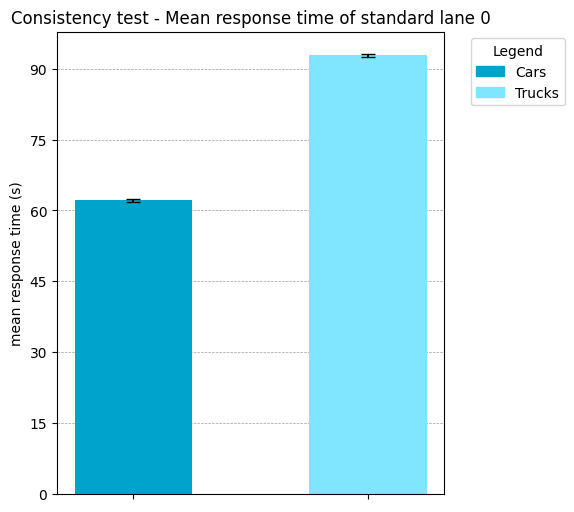

In [224]:
dictionary = GroupScalarsByConfigurationParameter(
      CONSISTENCY_TEST_onlyCars,
      STD_LANE_0,
      RESPONSE_TIME_STAT,
      CONFIG_PARAM_cars_arrival_rate)

dictionary2 = GroupScalarsByConfigurationParameter(
      CONSISTENCY_TEST_onlyTrucks,
      STD_LANE_0,
      RESPONSE_TIME_STAT,
      CONFIG_PARAM_cars_arrival_rate)

dictionary.update(dictionary2)

colors = [ '#00a3cc', '#80e5ff']
plt = ConstructBarChart(
      dictionary, 
      0.95, 
      colors, None, 5, 6)

plt.title("Consistency test - Mean response time of standard lane 0")
plt.ylabel("mean response time (s)")
plt.xlabel("")
plt.yticks(range(0, 100, 15))

plt.gca().set_xticklabels([])

# Label data
labels = [f'Cars', f'Trucks']
handles = [Rectangle((0, 0), 1, 1, color=color) for color in colors]
# Add the legend manually
plt.legend(handles=handles, labels=labels, loc='upper left', title="Legend", bbox_to_anchor=(1.05, 1))

if SAVE_GRAPH_FILES:
      fileName = 'test_consistency_cars_vs_trucks'
      plt.savefig(f'graphs/png/{fileName}.png', bbox_inches='tight')
      plt.savefig(f'graphs/jpg/{fileName}.jpg', bbox_inches='tight')
if SHOW_GRAPHS:
      plt.show()



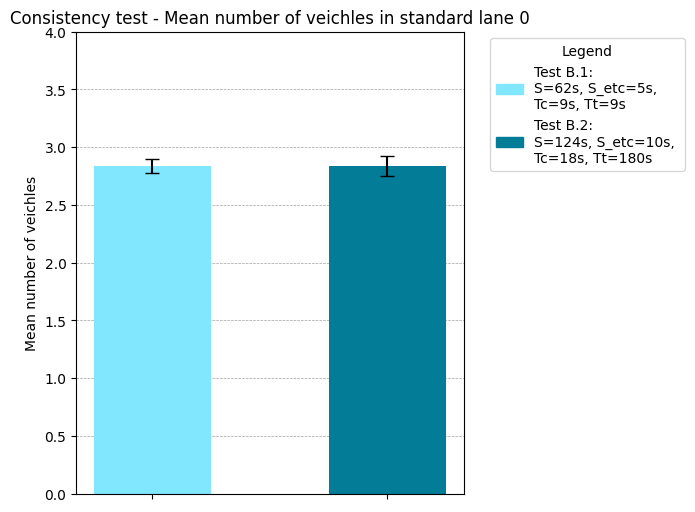

In [225]:
dict_std_gen = GroupScalarsByConfigurationParameter(
      GENERAL,
      STD_LANE_0,
      TOTAL_CARS_STAT,
      CONFIG_PARAM_cars_arrival_rate)

dict_std_double = GroupScalarsByConfigurationParameter(
      CONSISTENCY_TEST_DOUBLE_RATES,
      STD_LANE_0,
      TOTAL_CARS_STAT,
      CONFIG_PARAM_cars_arrival_rate)

# Merge the dictionaries
dictionary = {}

# Update the combined dictionary with each dictionary
dictionary.update(dict_std_gen)
dictionary.update(dict_std_double)

colors = ['#81e7fe', '#027c97']

plt = ConstructBarChart(
      dictionary, 
      0.95, 
      colors,
      None,
      5, 6)

plt.title("Consistency test - Mean number of veichles in standard lane 0")
plt.ylabel("Mean number of veichles")

plt.ylim(0, 4)

plt.xlabel("")
plt.gca().set_xticklabels([])

# Label data
labels = [f'Test B.1: \nS={62}s, S_etc={5}s, \nTc={9}s, Tt={9}s', f'Test B.2: \nS={124}s, S_etc={10}s, \nTc={18}s, Tt={180}s']
handles = [Rectangle((0, 0), 1, 1, color=color) for color in colors]
# Add the legend manually
plt.legend(handles=handles, labels=labels, loc='upper left', title="Legend", bbox_to_anchor=(1.05, 1))

if SAVE_GRAPH_FILES:
      fileName = 'test_consistency_doubleRates_stdOnly'
      plt.savefig(f'graphs/png/{fileName}.png', bbox_inches='tight')
      plt.savefig(f'graphs/jpg/{fileName}.jpg', bbox_inches='tight')
if SHOW_GRAPHS:
      plt.show()


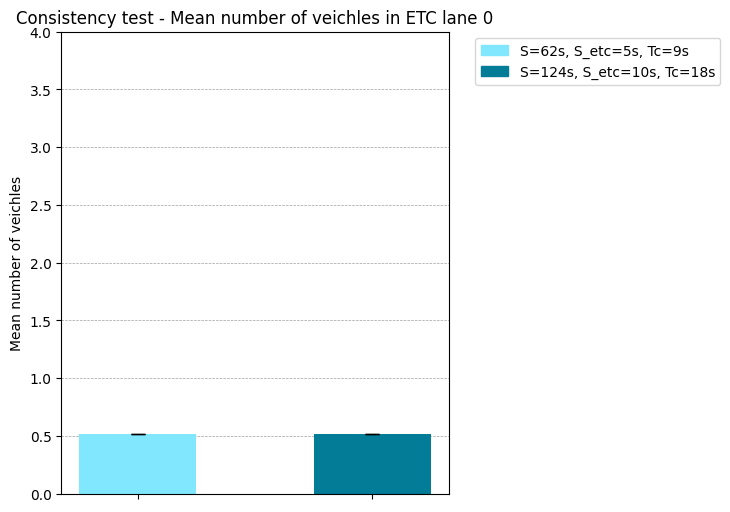

In [226]:
dict_etc_gen = GroupScalarsByConfigurationParameter(
      GENERAL,
      ETC_LANE_0,
      TOTAL_CARS_STAT,
      CONFIG_PARAM_cars_arrival_rate)

dict_etc_double = GroupScalarsByConfigurationParameter(
      CONSISTENCY_TEST_DOUBLE_RATES,
      ETC_LANE_0,
      TOTAL_CARS_STAT,
      CONFIG_PARAM_cars_arrival_rate)
# Merge the dictionaries
dictionary = {}

# Update the combined dictionary with each dictionary
dictionary.update(dict_etc_gen)
dictionary.update(dict_etc_double)

colors = ['#81e7fe', '#027c97']

plt = ConstructBarChart(
      dictionary, 
      0.95, 
      colors,
      None,
      5, 6)

plt.title("Consistency test - Mean number of veichles in ETC lane 0")
plt.ylabel("Mean number of veichles")

plt.ylim(0, 4)

plt.xlabel("")
plt.gca().set_xticklabels([])

# Label data
labels = [f'S={62}s, S_etc={5}s, Tc={9}s', f'S={124}s, S_etc={10}s, Tc={18}s']
handles = [Rectangle((0, 0), 1, 1, color=color) for color in colors]
# Add the legend manually
plt.legend(handles=handles, labels=labels, loc='upper left', bbox_to_anchor=(1.05, 1))

if SAVE_GRAPH_FILES:
      fileName = 'test_consistency_doubleRates_etcOnly'
      plt.savefig(f'graphs/png/{fileName}.png', bbox_inches='tight')
      plt.savefig(f'graphs/jpg/{fileName}.jpg', bbox_inches='tight')
if SHOW_GRAPHS:
      plt.show()


The number of queued cars stays roughly constant (they arrive more slowly but are also served more slowly)

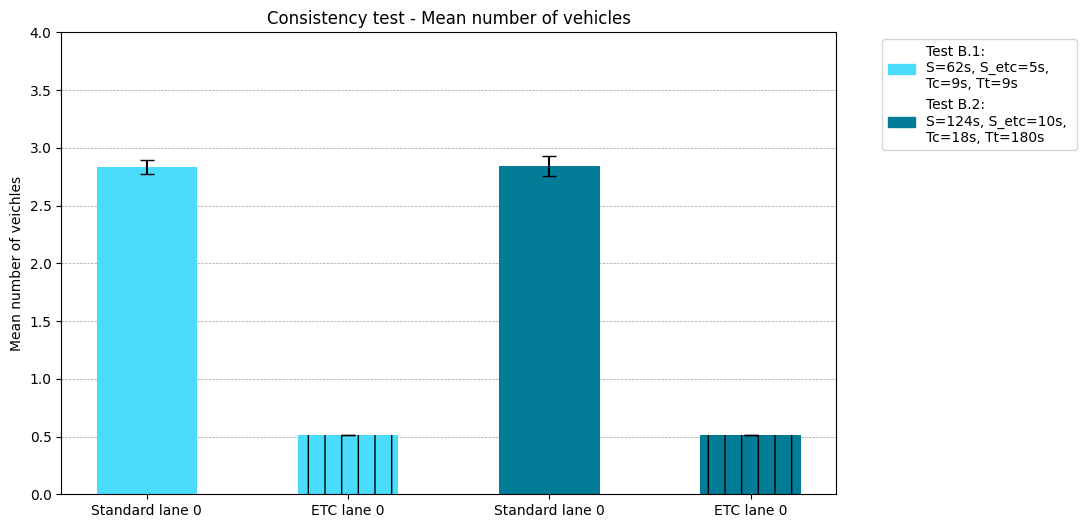

In [227]:
dict_std_gen = GroupScalarsByConfigurationParameter(
      GENERAL,
      STD_LANE_0,
      TOTAL_CARS_STAT,
      CONFIG_PARAM_cars_arrival_rate)
# rename the key
dict_std_gen["1"] = dict_std_gen.pop("9")

dict_etc_gen = GroupScalarsByConfigurationParameter(
      GENERAL,
      ETC_LANE_0,
      TOTAL_CARS_STAT,
      CONFIG_PARAM_cars_arrival_rate)
# rename the key
dict_etc_gen["2"] = dict_etc_gen.pop("9")


dict_std_double = GroupScalarsByConfigurationParameter(
      CONSISTENCY_TEST_DOUBLE_RATES,
      STD_LANE_0,
      TOTAL_CARS_STAT,
      CONFIG_PARAM_cars_arrival_rate)
# rename the key
dict_std_double["4"] = dict_std_double.pop("18")


dict_etc_double = GroupScalarsByConfigurationParameter(
      CONSISTENCY_TEST_DOUBLE_RATES,
      ETC_LANE_0,
      TOTAL_CARS_STAT,
      CONFIG_PARAM_cars_arrival_rate)
# rename the key
dict_etc_double["5"] = dict_etc_double.pop("18")

# Merge the dictionaries
dictionary = {}

# Update the combined dictionary with each dictionary
dictionary.update(dict_std_gen)
dictionary.update(dict_std_double)
dictionary.update(dict_etc_gen)
dictionary.update(dict_etc_double)


colors = ['#4adcfd', '#4adcfd', '#027c97', '#027c97']

hatches = [None, '|', None, '|']  # Bar hatches
plt = ConstructBarChart(
      dictionary, 
      0.95, 
      colors,
      hatches,
      10, 6)

plt.title("Consistency test - Mean number of vehicles")
plt.ylabel("Mean number of veichles")

plt.ylim(0, 4)

plt.xlabel("")
tick_labels = ['Standard lane 0', 'ETC lane 0', 'Standard lane 0', 'ETC lane 0']
plt.xticks(ticks=range(len(tick_labels)), labels=tick_labels)  # Set ticks and labels

# plt.gca().set_xticklabels([])

# Label data
labels = [f'Test B.1: \nS={62}s, S_etc={5}s, \nTc={9}s, Tt={9}s', f'Test B.2: \nS={124}s, S_etc={10}s, \nTc={18}s, Tt={180}s']
selected_colors = [colors[0], colors[2]]
handles = [Rectangle((0, 0), 1, 1, color=color) for color in selected_colors]

# Add the legend manually
plt.legend(handles=handles, labels=labels, loc='upper left', bbox_to_anchor=(1.05, 1))

if SAVE_GRAPH_FILES:
      fileName = 'test_consistency_doubleRates'
      plt.savefig(f'graphs/png/{fileName}.png', bbox_inches='tight')
      plt.savefig(f'graphs/jpg/{fileName}.jpg', bbox_inches='tight')
if SHOW_GRAPHS:
      plt.show()
